In [17]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
import datetime



# Configuration
DATA_PATH = './data'  # Dossier où stocker CelebA
BATCH_SIZE = 64
IMAGE_SIZE = 64       # On redimensionne en 64x64 pour simplifier le modèle V1
Z_DIM = 100           # Taille du vecteur de bruit
NUM_EPOCHS = 10       # Commence petit pour tester, augmente à 50+ pour de vrais résultats
LR = 0.0002           # Learning rate standard pour DCGAN
BETA1 = 0.5           # Hyperparamètre Adam
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Attributs choisis (Indices dans CelebA)
# Tu peux changer cette liste. CelebA a 40 attributs.
# Exemples: 20: Male, 9: Blond_Hair, 31: Smiling, 15: Eyeglasses
SELECTED_ATTR_INDICES = [20, 9, 31] 
ATTR_NAMES = ['Male', 'Blond_Hair', 'Smiling']
NUM_CLASSES = len(SELECTED_ATTR_INDICES)

print(f"Utilisation de : {DEVICE}")

Utilisation de : mps


In [7]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# --- CONFIGURATION DES CHEMINS ---
# Mets le chemin vers ton dossier "archive"
ROOT_DIR = "./data" 

# Chemin vers le fichier CSV des attributs
ATTR_FILE = os.path.join(ROOT_DIR, "list_attr_celeba.csv")

# Chemin vers le dossier contenant les images .jpg
# Attention : sur ton screen il y a deux fois "img_align_celeba" imbriqué
IMG_DIR = os.path.join(ROOT_DIR, "img_align_celeba/img_align_celeba")

# --- CUSTOM DATASET CLASS ---
class CustomCelebA(Dataset):
    def __init__(self, img_dir, attr_path, selected_attrs, transform=None):
        """
        Args:
            img_dir (string): Dossier avec les images.
            attr_path (string): Chemin vers le CSV des attributs.
            selected_attrs (list): Liste des noms de colonnes qu'on veut (ex: ['Smiling']).
            transform (callable, optional): Transformations à appliquer sur l'image.
        """
        self.img_dir = img_dir
        self.transform = transform
        
        # Lecture du CSV avec Pandas
        # On assume que c'est le format Kaggle (séparateur virgule)
        self.attr_df = pd.read_csv(attr_path)
        
        # Vérification que les colonnes existent
        self.selected_attrs = selected_attrs
        
        # Stockage des noms d'images (la colonne s'appelle souvent 'image_id' ou est l'index)
        # Dans le CSV Kaggle standard, la première colonne est le nom du fichier
        self.image_names = self.attr_df.iloc[:, 0].values
        
        # On récupère uniquement les valeurs des attributs choisis
        # On convertit les valeurs -1 (pas l'attribut) en 0, et 1 (a l'attribut) en 1
        # CelebA natif est en -1/1, BCELoss veut du 0/1.
        self.labels = self.attr_df[selected_attrs].values
        self.labels = (self.labels + 1) // 2 

    def __len__(self):
        return len(self.attr_df)

    def __getitem__(self, idx):
        # 1. Charger l'image
        img_name = self.image_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        
        try:
            image = Image.open(img_path).convert('RGB')
        except FileNotFoundError:
            # Sécurité si une image est manquante
            print(f"Image introuvable : {img_path}")
            return self.__getitem__((idx + 1) % len(self))

        # 2. Appliquer les transformations
        if self.transform:
            image = self.transform(image)

        # 3. Récupérer les labels
        attr = torch.tensor(self.labels[idx]).float()

        return image, attr

# --- SETUP DU DATALOADER ---

# Définition des attributs que tu veux (doivent correspondre aux noms exacts dans le CSV)
# Ouvre ton CSV pour vérifier, mais généralement c'est : 'Male', 'Blond_Hair', 'Smiling'
SELECTED_ATTR_NAMES = ['Male', 'Blond_Hair', 'Smiling']
NUM_CLASSES = len(SELECTED_ATTR_NAMES)

# Transformations
transform = transforms.Compose([
    transforms.Resize((64, 64)), # Taille requise pour le modèle
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Création de l'instance
dataset = CustomCelebA(
    img_dir=IMG_DIR,
    attr_path=ATTR_FILE,
    selected_attrs=SELECTED_ATTR_NAMES,
    transform=transform
)

# DataLoader
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

# Vérification
print(f"Dataset chargé avec {len(dataset)} images.")
real_batch, real_labels = next(iter(dataloader))
print(f"Exemple de labels (Batch shape): {real_labels.shape}")

Dataset chargé avec 202599 images.
Exemple de labels (Batch shape): torch.Size([64, 3])


In [8]:
# Initialisation des poids (Bonne pratique DCGAN)
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

# --- GENERATOR ---
class Generator(nn.Module):
    def __init__(self, z_dim, num_classes):
        super(Generator, self).__init__()
        # Input: z + labels
        self.input_dim = z_dim + num_classes
        
        self.main = nn.Sequential(
            # Input is Z, going into a convolution
            nn.ConvTranspose2d(self.input_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            # State size: (512) x 4 x 4
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # State size: (256) x 8 x 8
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # State size: (128) x 16 x 16
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # State size: (64) x 32 x 32
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
            # Output size: (3) x 64 x 64
        )

    def forward(self, noise, labels):
        # Concaténation du bruit et des labels
        # labels shape: [Batch, Num_Classes] -> on reshape pour concaténer
        labels = labels.unsqueeze(2).unsqueeze(3) # [B, N, 1, 1]
        gen_input = torch.cat((noise, labels), 1)
        return self.main(gen_input)

# --- DISCRIMINATOR ---
class Discriminator(nn.Module):
    def __init__(self, num_classes):
        super(Discriminator, self).__init__()
        # Input: Image (3 channels) + Labels (Num_classes channels)
        self.input_dim = 3 + num_classes
        
        self.main = nn.Sequential(
            # input is (input_dim) x 64 x 64
            nn.Conv2d(self.input_dim, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (64) x 32 x 32
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (128) x 16 x 16
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (256) x 8 x 8
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (512) x 4 x 4
            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        # On doit étendre les labels pour qu'ils aient la même taille spatiale que l'image (64x64)
        # Labels: [Batch, N] -> [Batch, N, 64, 64]
        labels = labels.unsqueeze(2).unsqueeze(3)
        labels = labels.repeat(1, 1, img.size(2), img.size(3))
        
        disc_input = torch.cat((img, labels), 1)
        return self.main(disc_input)

# Instanciation
netG = Generator(Z_DIM, NUM_CLASSES).to(DEVICE)
netD = Discriminator(NUM_CLASSES).to(DEVICE)
netG.apply(weights_init)
netD.apply(weights_init)

print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(103, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


In [6]:
import os
import datetime
# --- 1. CONFIGURATION DU RUN UNIQUE ---
# On crée un nom unique pour ce lancement basé sur l'heure
run_name = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
print(f"🚀 Lancement du Run : {run_name}")

# Dossiers spécifiques pour ce run
log_dir = os.path.join("logs", "cgan_celeba", run_name)
ckpt_dir = os.path.join("checkpoints", run_name)

os.makedirs(ckpt_dir, exist_ok=True)

# Loss & Optimizers
criterion = nn.BCELoss()

optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

# Création d'un nom unique basé sur l'heure actuelle
# Ex: logs/cgan_celeba/2023-10-27_14-30-00
log_dir_name = os.path.join('logs', 'cgan_celeba', datetime.now().strftime('%Y-%m-%d_%H-%M-%S'))

# Initialisation du writer dans ce sous-dossier unique
writer = SummaryWriter(log_dir_name)


# Labels fixes pour suivre la progression visuellement
fixed_noise = torch.randn(64, Z_DIM, 1, 1, device=DEVICE)
fixed_labels = (torch.rand(64, NUM_CLASSES, device=DEVICE) > 0.5).float() 

print("Début de l'entraînement...")

step = 0
for epoch in range(NUM_EPOCHS):
    for i, (data, labels) in enumerate(dataloader):
        data = data.to(DEVICE)
        labels = labels.float().to(DEVICE)
        b_size = data.size(0)

        # ---------------------
        # 1. Train Discriminator
        # ---------------------
        netD.zero_grad()
        
        # Real
        label_real = torch.full((b_size,), 1., device=DEVICE)
        output_real = netD(data, labels).view(-1)
        errD_real = criterion(output_real, label_real)
        errD_real.backward()
        
        # Fake
        noise = torch.randn(b_size, Z_DIM, 1, 1, device=DEVICE)
        fake_data = netG(noise, labels)
        label_fake = torch.full((b_size,), 0., device=DEVICE)
        
        output_fake = netD(fake_data.detach(), labels).view(-1)
        errD_fake = criterion(output_fake, label_fake)
        errD_fake.backward()
        
        errD = errD_real + errD_fake
        optimizerD.step()

        # -----------------
        # 2. Train Generator
        # -----------------
        netG.zero_grad()
        label_real = torch.full((b_size,), 1., device=DEVICE)
        output = netD(fake_data, labels).view(-1)
        errG = criterion(output, label_real)
        errG.backward()
        optimizerG.step()

        # Logging
        if i % 50 == 0:
            print(f'[{epoch}/{NUM_EPOCHS}][{i}/{len(dataloader)}] Loss_D: {errD.item():.4f} Loss_G: {errG.item():.4f}')
            writer.add_scalar('Loss/Discriminator', errD.item(), step)
            writer.add_scalar('Loss/Generator', errG.item(), step)
            step += 1

    # --- FIN DE L'EPOCH ---

    # 1. Tensorboard Update
    with torch.no_grad():
        fake = netG(fixed_noise, fixed_labels).detach().cpu()
        grid = vutils.make_grid(fake, padding=2, normalize=True)
        writer.add_image('Images_Générées', grid, epoch)
    
    # 2. SAUVEGARDE DES POIDS (CHECKPOINTS)
    # 2. Sauvegarde des Checkpoints dans le dossier du Run
    torch.save(netG.state_dict(), os.path.join(ckpt_dir, f'netG_epoch_{epoch}.pth'))
    torch.save(netD.state_dict(), os.path.join(ckpt_dir, f'netD_epoch_{epoch}.pth'))
    
    print(f"--> Epoch {epoch} terminée. Checkpoint sauvegardé dans {ckpt_dir}")

print("Entraînement terminé.")
writer.close()

AttributeError: module 'datetime' has no attribute 'now'

In [15]:
def generate_specific_face(attr_dict, model_path=None):
    """
    attr_dict: Dictionnaire {index_attribut: 0 ou 1}
    model_path: Chemin vers le fichier .pth.
                Structure attendue : 'checkpoints/NOM_DU_RUN/netG_epoch_X.pth'
    """
    
    # --- 1. LOGIQUE D'ORGANISATION DES DOSSIERS ---
    if model_path is not None:
        if os.path.exists(model_path):
            # A. Chargement des poids
            netG.load_state_dict(torch.load(model_path, map_location=DEVICE))
            print(f"Chargement : {model_path}")
            
            # B. Extraction du Nom du Run et de l'Epoch via le chemin du fichier
            # Ex: checkpoints/2023-11-26_14-00/netG_epoch_9.pth
            
            # Récupère le dossier parent (le nom du run) -> "2023-11-26_14-00"
            run_name = os.path.basename(os.path.dirname(model_path))
            
            # Récupère le nom du fichier -> "netG_epoch_9.pth"
            filename = os.path.basename(model_path)
            
            # Extrait le numéro de l'époque (si le format est respecté)
            if "epoch" in filename:
                # Coupe "netG_epoch_9.pth" pour garder "9"
                epoch_num = filename.split('_')[-1].replace('.pth', '')
                epoch_folder = f"epoch_{epoch_num}"
            else:
                epoch_folder = "custom_model"
                
        else:
            print(f"Erreur : Le fichier {model_path} n'existe pas.")
            return
    else:
        # Si on utilise le modèle en mémoire vive (juste après entrainement)
        run_name = "live_session"
        epoch_folder = "latest_memory"

    # C. Création du chemin final
    # generated_results / 2023-11-26... / epoch_9 /
    save_dir = os.path.join('generated_results', run_name, epoch_folder)
    os.makedirs(save_dir, exist_ok=True)

    # --- 2. GENERATION ---
    netG.eval()
    with torch.no_grad():
        labels = torch.zeros(1, NUM_CLASSES).to(DEVICE)
        
        # Construction du nom de l'image (ex: Male_1_Blond_0...)
        attr_str_list = []
        for idx, val in attr_dict.items():
            labels[0, idx] = val
            attr_name = SELECTED_ATTR_NAMES[idx] if 'SELECTED_ATTR_NAMES' in globals() else f"Attr{idx}"
            attr_str_list.append(f"{attr_name}_{val}")
        
        attr_filename = "_".join(attr_str_list) + ".png"

        # Génération
        noise = torch.randn(1, Z_DIM, 1, 1, device=DEVICE)
        fake_image = netG(noise, labels).cpu()
        
        # --- 3. AFFICHAGE & SAUVEGARDE ---
        plt.figure(figsize=(4, 4))
        plt.axis("off")
        # Titre informatif
        plt.title(f"Run: {run_name}\nEpoch: {epoch_folder}\nAttr: {list(attr_dict.values())}", fontsize=8)
        
        grid_img = vutils.make_grid(fake_image, normalize=True)
        plt.imshow(np.transpose(grid_img, (1,2,0)))
        
        # Sauvegarde
        save_path = os.path.join(save_dir, attr_filename)
        plt.savefig(save_path, bbox_inches='tight')
        plt.show()
        
        print(f"📁 Image sauvegardée dans : {save_path}")

Test du modèle : checkpoints/2025-11-26_14-30-00/netG_epoch_9.pth
Chargement : checkpoints/2025-11-26_14-30-00/netG_epoch_9.pth


/var/folders/qw/06dxj3m91kv23yphm00crzz00000gn/T/ipykernel_89593/934023256.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  netG.load_state_dict(torch.load(model_path, m

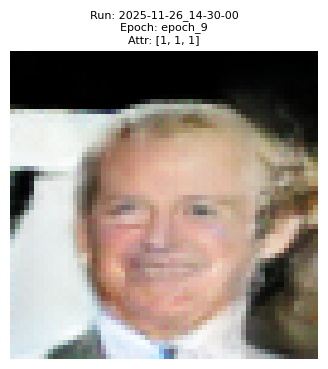

📁 Image sauvegardée dans : generated_results/2025-11-26_14-30-00/epoch_9/Male_1_Blond_Hair_1_Smiling_1.png
Chargement : checkpoints/2025-11-26_14-30-00/netG_epoch_9.pth


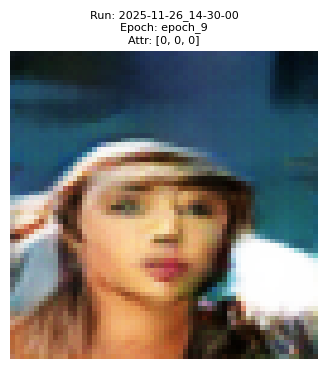

📁 Image sauvegardée dans : generated_results/2025-11-26_14-30-00/epoch_9/Male_0_Blond_Hair_0_Smiling_0.png


In [16]:
# 1. Tu définis le dossier du run (regarde dans tes fichiers pour trouver le nom exact)
run_id = "2025-11-26_14-30-00" 

# 2. Tu définis l'époque
epoch = 9

# 3. Tu construis le chemin
path = os.path.join("checkpoints", run_id, f"netG_epoch_{epoch}.pth")

# 4. Tu génères
print(f"Test du modèle : {path}")

# Test Homme Blond Souriant
generate_specific_face({0: 1, 1: 1, 2: 1}, model_path=path)

# Test Femme Brune Pas souriante
generate_specific_face({0: 0, 1: 0, 2: 0}, model_path=path)